<a href="https://colab.research.google.com/github/anuramvarma/System-Design-Notes/blob/main/Waste_Image_Classification_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install required supporting libraries

!pip install -q numpy pandas matplotlib scikit-learn pillow seaborn

In [2]:
# Import essential libraries

import os
import random
import shutil
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Display library versions

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

# Check GPU availability

print("\nGPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)
print("Available Devices:", tf.config.list_physical_devices())

TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
Pandas Version: 2.2.3

GPU Available: True
Available Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Set random seeds for reproducibility

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seeds configured successfully!")

Random seeds configured successfully!


In [4]:
# Define project directory

PROJECT_DIR = "/content/Waste_Image_Classification"

# Create required directories

DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(DATASET_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Project directories created successfully!")

print("\nProject Location:", PROJECT_DIR)
print("Dataset Location:", DATASET_DIR)
print("Output Location:", OUTPUT_DIR)
print("Model Location:", MODEL_DIR)

Project directories created successfully!

Project Location: /content/Waste_Image_Classification
Dataset Location: /content/Waste_Image_Classification/dataset
Output Location: /content/Waste_Image_Classification/outputs
Model Location: /content/Waste_Image_Classification/models


In [5]:
# Download the TrashNet repository

import subprocess

REPO_DIR = "/content/trashnet_repo"

if not os.path.exists(REPO_DIR):
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/garythung/trashnet.git",
            REPO_DIR
        ],
        check=True
    )

print("TrashNet repository downloaded successfully!")

TrashNet repository downloaded successfully!


In [6]:
# Search for the resized dataset ZIP

repo_path = Path(REPO_DIR)

zip_files = list(repo_path.rglob("dataset-resized.zip"))

if zip_files:
    DATASET_ZIP = zip_files[0]
    print("Dataset ZIP found:", DATASET_ZIP)

else:
    print("Dataset ZIP not found in repository.")
    print("Please upload dataset-resized.zip.")

    from google.colab import files

    uploaded = files.upload()

    zip_names = [
        name for name in uploaded.keys()
        if name.lower().endswith(".zip")
    ]

    if not zip_names:
        raise FileNotFoundError(
            "Please upload the dataset-resized.zip file."
        )

    DATASET_ZIP = Path("/content") / zip_names[0]

# Extract dataset

EXTRACT_DIR = "/content/trashnet_extracted"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(DATASET_ZIP, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("\nDataset extracted successfully!")

Dataset ZIP found: /content/trashnet_repo/data/dataset-resized.zip

Dataset extracted successfully!


In [7]:
# Define required waste categories

CLASS_NAMES = [
    "paper",
    "plastic",
    "glass",
    "metal"
]

# Locate the directory containing all six TrashNet classes

ALL_CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

source_root = None

for root, dirs, files in os.walk(EXTRACT_DIR):

    available_dirs = {
        directory.lower() for directory in dirs
    }

    if set(ALL_CLASSES).issubset(available_dirs):
        source_root = Path(root)
        break

if source_root is None:
    raise FileNotFoundError(
        "Could not find the six TrashNet class folders. "
        "Check the extracted ZIP structure."
    )

print("Original dataset location:", source_root)

# Prepare our four-class dataset

for class_name in CLASS_NAMES:

    source_folder = source_root / class_name
    destination_folder = Path(DATASET_DIR) / class_name

    if destination_folder.exists():
        shutil.rmtree(destination_folder)

    shutil.copytree(source_folder, destination_folder)

print("\nFour required categories copied successfully!")

for class_name in CLASS_NAMES:
    print("✔", class_name)

Original dataset location: /content/trashnet_extracted/dataset-resized

Four required categories copied successfully!
✔ paper
✔ plastic
✔ glass
✔ metal


In [8]:
# Count images in each category

image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

class_counts = {}

for class_name in CLASS_NAMES:

    folder_path = Path(DATASET_DIR) / class_name

    image_files = [
        file for file in folder_path.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    class_counts[class_name] = len(image_files)

# Convert results into a Pandas DataFrame

class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Waste Category", "Number of Images"]
)

print("Dataset Summary:\n")
print(class_df.to_string(index=False))

print("\nTotal Images:", sum(class_counts.values()))

Dataset Summary:

Waste Category  Number of Images
         paper               594
       plastic               482
         glass               501
         metal               410

Total Images: 1987


In [9]:
# Create dataset metadata

image_records = []

for class_name in CLASS_NAMES:

    folder_path = Path(DATASET_DIR) / class_name

    for image_path in folder_path.iterdir():

        if image_path.suffix.lower() not in image_extensions:
            continue

        try:
            with Image.open(image_path) as img:

                width, height = img.size

                image_records.append({
                    "image_path": str(image_path),
                    "label": class_name,
                    "width": width,
                    "height": height
                })

        except Exception as error:
            print("Invalid image:", image_path, error)

# Create DataFrame

df = pd.DataFrame(image_records)

print("Dataset Metadata:")
display(df.head(10))

print("\nDataset Shape:", df.shape)

print("\nCategory Information:")
print(df["label"].value_counts())

Dataset Metadata:


,image_path,label,width,height
0,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
1,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
2,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
3,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
4,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
5,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
6,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
7,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
8,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
9,/content/Waste_Image_Classification/dataset/pa...,paper,512,384



Dataset Shape: (1987, 4)

Category Information:
label
paper      594
glass      501
plastic    482
metal      410
Name: count, dtype: int64


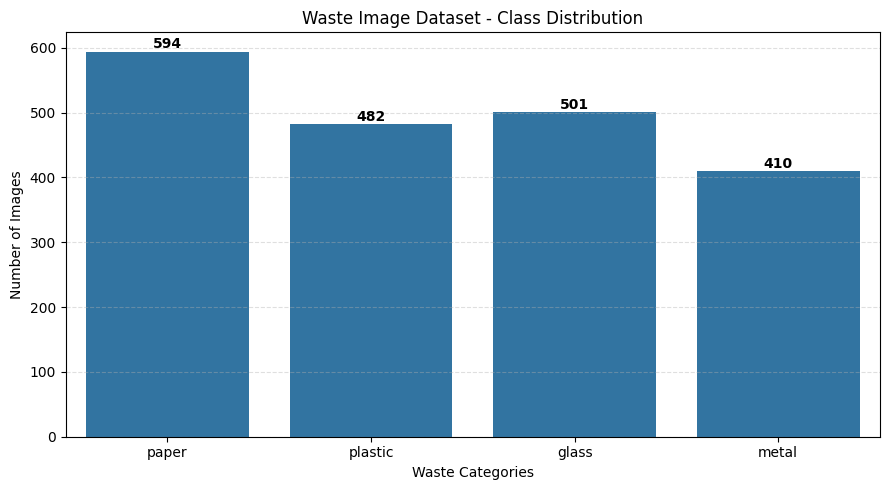

In [10]:
# Calculate class distribution

distribution = df["label"].value_counts().reindex(CLASS_NAMES)

# Plot class distribution

plt.figure(figsize=(9, 5))

sns.barplot(
    x=distribution.index,
    y=distribution.values
)

plt.title("Waste Image Dataset - Class Distribution")
plt.xlabel("Waste Categories")
plt.ylabel("Number of Images")

plt.grid(axis="y", linestyle="--", alpha=0.4)

# Display image counts above bars

for index, value in enumerate(distribution.values):

    plt.text(
        index,
        value + 5,
        str(value),
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

# Save graph for project report

plt.savefig(
    os.path.join(OUTPUT_DIR, "class_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

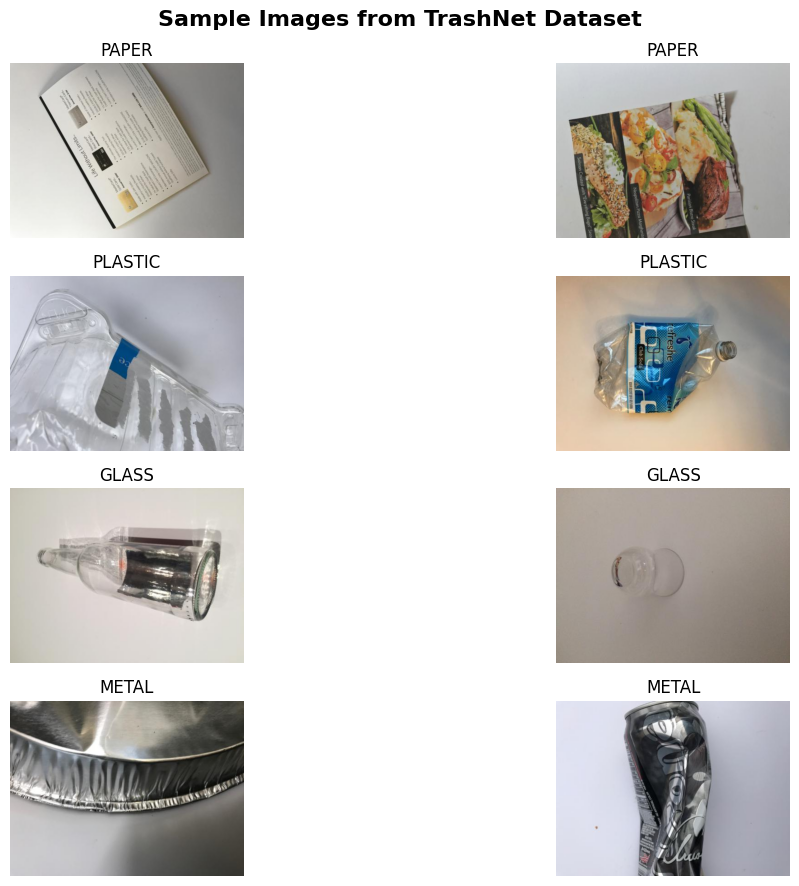

In [11]:
# Display sample images from each category

plt.figure(figsize=(14, 9))

for index, class_name in enumerate(CLASS_NAMES):

    folder_path = Path(DATASET_DIR) / class_name

    image_files = [
        file for file in folder_path.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    # Select two random images

    selected_images = random.sample(
        image_files,
        min(2, len(image_files))
    )

    for j, image_path in enumerate(selected_images):

        plt.subplot(4, 2, index * 2 + j + 1)

        img = Image.open(image_path).convert("RGB")

        plt.imshow(img)

        plt.title(class_name.upper())

        plt.axis("off")

plt.suptitle(
    "Sample Images from TrashNet Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "sample_images.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Final dataset verification

print("=" * 50)
print("WASTE IMAGE CLASSIFICATION - DATASET SUMMARY")
print("=" * 50)

print("Dataset Name: TrashNet")
print("Project: Waste Image Classification Using CNN")

print("\nSelected Categories:")

for class_name in CLASS_NAMES:

    count = class_counts[class_name]

    print(f"{class_name.capitalize():<15}: {count} images")

print("\nTotal Valid Images:", len(df))

print("Number of Classes:", len(CLASS_NAMES))

print("Image Format: JPEG / PNG / BMP")

print("Dataset Location:", DATASET_DIR)

print("\nGenerated Outputs:")

print("1. class_distribution.png")
print("2. sample_images.png")

print("\nDATASET PREPARATION COMPLETED!")
print("=" * 50)

WASTE IMAGE CLASSIFICATION - DATASET SUMMARY
Dataset Name: TrashNet
Project: Waste Image Classification Using CNN

Selected Categories:
Paper          : 594 images
Plastic        : 482 images
Glass          : 501 images
Metal          : 410 images

Total Valid Images: 1987
Number of Classes: 4
Image Format: JPEG / PNG / BMP
Dataset Location: /content/Waste_Image_Classification/dataset

Generated Outputs:
1. class_distribution.png
2. sample_images.png

DATASET PREPARATION COMPLETED!


**Image Preprocessing and Dataset Splitting**

In [13]:
# Verify dataset from Step 1

print("Dataset Shape:", df.shape)

print("\nAvailable Categories:")
print(CLASS_NAMES)

print("\nImage Records:")
display(df.head())

print("\nTotal Images:", len(df))

print("\nClass Distribution:")
print(df["label"].value_counts())

Dataset Shape: (1987, 4)

Available Categories:
['paper', 'plastic', 'glass', 'metal']

Image Records:


,image_path,label,width,height
0,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
1,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
2,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
3,/content/Waste_Image_Classification/dataset/pa...,paper,512,384
4,/content/Waste_Image_Classification/dataset/pa...,paper,512,384



Total Images: 1987

Class Distribution:
label
paper      594
glass      501
plastic    482
metal      410
Name: count, dtype: int64


In [14]:
# Image preprocessing configuration

IMG_HEIGHT = 128
IMG_WIDTH = 128
CHANNELS = 3

IMAGE_SIZE = (IMG_HEIGHT, IMG_WIDTH)

# Define class labels

CLASS_NAMES = ["paper", "plastic", "glass", "metal"]

NUM_CLASSES = len(CLASS_NAMES)

# Create numerical label mapping

class_to_index = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

print("Image Size:", IMAGE_SIZE)
print("Number of Channels:", CHANNELS)
print("Number of Classes:", NUM_CLASSES)

print("\nClass Encoding:")
print(class_to_index)

Image Size: (128, 128)
Number of Channels: 3
Number of Classes: 4

Class Encoding:
{'paper': 0, 'plastic': 1, 'glass': 2, 'metal': 3}


In [15]:
# Step 1: Split 70% for training and 30% for temporary data

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

# Step 2: Divide temporary data equally into validation and testing

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

# Reset DataFrame indexes

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Display split information

print("DATASET SPLITTING RESULTS")
print("=" * 40)

print("Training Images  :", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images   :", len(test_df))

print("\nTotal Images:", len(train_df) + len(val_df) + len(test_df))

DATASET SPLITTING RESULTS
Training Images  : 1390
Validation Images: 298
Testing Images   : 299

Total Images: 1987


In [16]:
# Calculate class distribution for each dataset

split_distribution = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).reindex(CLASS_NAMES).fillna(0).astype(int)

print("CLASS DISTRIBUTION AFTER SPLITTING\n")

display(split_distribution)

# Calculate percentages

print("\nDATASET SPLIT PERCENTAGES")

total_images = len(df)

for name, dataset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:

    percentage = len(dataset) / total_images * 100

    print(f"{name}: {percentage:.2f}%")

CLASS DISTRIBUTION AFTER SPLITTING



,Training,Validation,Testing
label,,,
paper,416,89,89
plastic,337,72,73
glass,350,75,76
metal,287,62,61



DATASET SPLIT PERCENTAGES
Training: 69.95%
Validation: 15.00%
Testing: 15.05%


In [17]:
# Function to load and resize images

def preprocess_image(image_path):

    # Open the image
    image = Image.open(image_path)

    # Convert image into RGB format
    image = image.convert("RGB")

    # Resize image to 128 x 128
    image = image.resize(
        IMAGE_SIZE,
        Image.Resampling.BILINEAR
    )

    # Convert image into NumPy array
    image_array = np.array(image, dtype=np.float32)

    return image_array


print("Image preprocessing function created successfully!")

Image preprocessing function created successfully!


In [18]:
# Function to load images and their labels

def load_dataset(dataframe):

    images = []
    labels = []

    for _, row in dataframe.iterrows():

        # Get image path
        image_path = row["image_path"]

        # Get image label
        label = row["label"]

        # Preprocess image
        image = preprocess_image(image_path)

        # Convert label into numerical value
        encoded_label = class_to_index[label]

        images.append(image)
        labels.append(encoded_label)

    # Convert lists into NumPy arrays
    images = np.array(images, dtype=np.float32)
    labels = np.array(labels, dtype=np.int32)

    return images, labels


print("Image loading function created successfully!")

Image loading function created successfully!


In [19]:
# Load all three datasets

print("Loading training images...")

X_train, y_train = load_dataset(train_df)

print("Loading validation images...")

X_val, y_val = load_dataset(val_df)

print("Loading testing images...")

X_test, y_test = load_dataset(test_df)

print("\nAll images loaded successfully!")

Loading training images...
Loading validation images...
Loading testing images...

All images loaded successfully!


In [20]:
# Normalize image pixel values

X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

print("Image normalization completed!")

print("\nTraining Pixel Range:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

print("\nValidation Pixel Range:")
print("Minimum:", X_val.min())
print("Maximum:", X_val.max())

print("\nTesting Pixel Range:")
print("Minimum:", X_test.min())
print("Maximum:", X_test.max())

Image normalization completed!

Training Pixel Range:
Minimum: 0.0
Maximum: 1.0

Validation Pixel Range:
Minimum: 0.0
Maximum: 1.0

Testing Pixel Range:
Minimum: 0.0
Maximum: 1.0


In [21]:
# Display dataset shapes

print("=" * 50)
print("PREPROCESSED DATASET SHAPES")
print("=" * 50)

print("\nTraining Data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation Data:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTesting Data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nImage Data Type:", X_train.dtype)
print("Label Data Type:", y_train.dtype)

PREPROCESSED DATASET SHAPES

Training Data:
X_train: (1390, 128, 128, 3)
y_train: (1390,)

Validation Data:
X_val: (298, 128, 128, 3)
y_val: (298,)

Testing Data:
X_test: (299, 128, 128, 3)
y_test: (299,)

Image Data Type: float32
Label Data Type: int32


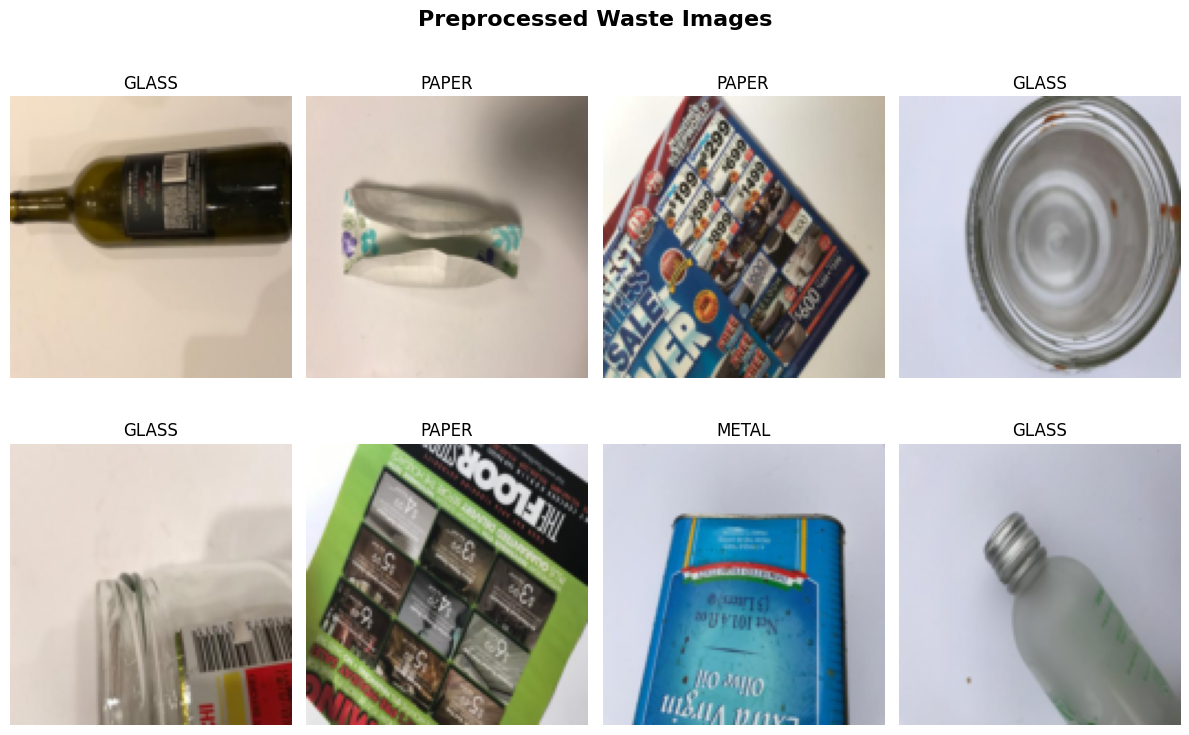

In [22]:
# Display normalized images

plt.figure(figsize=(12, 8))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    # Display image
    plt.imshow(X_train[i])

    # Convert numerical label into category
    label_name = index_to_class[y_train[i]]

    plt.title(label_name.upper())

    plt.axis("off")

plt.suptitle(
    "Preprocessed Waste Images",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save image for project report

plt.savefig(
    os.path.join(OUTPUT_DIR, "preprocessed_images.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Visualize the dataset split**

We will create a bar chart to compare the number of images in each dataset.

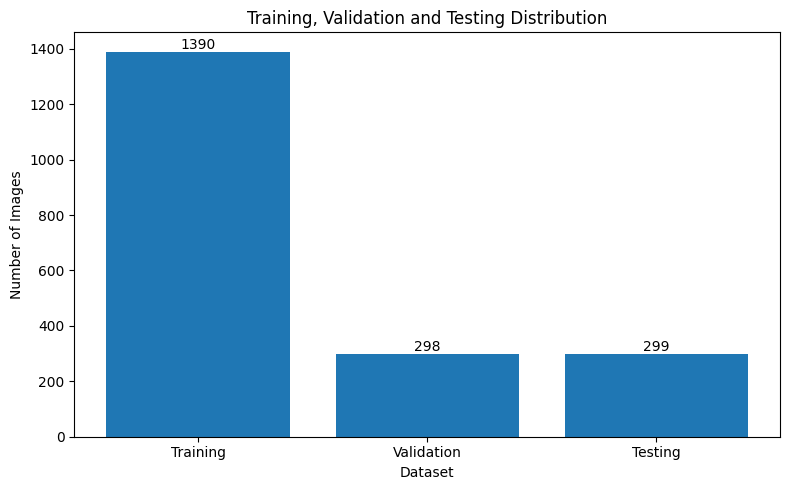

In [23]:
# Dataset splitting visualization

split_names = ["Training", "Validation", "Testing"]

split_counts = [
    len(X_train),
    len(X_val),
    len(X_test)
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    split_names,
    split_counts
)

plt.title("Training, Validation and Testing Distribution")

plt.xlabel("Dataset")
plt.ylabel("Number of Images")

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        int(height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "dataset_split.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Verify label encoding.**

Let's verify that our numerical labels correctly represent the four waste categories.

In [24]:
# Display label encoding

print("LABEL ENCODING VERIFICATION")
print("=" * 40)

for index, class_name in index_to_class.items():

    print(f"{class_name.capitalize()} = {index}")

print("\nTraining Label Samples:")
print(y_train[:15])

print("\nValidation Label Samples:")
print(y_val[:15])

print("\nTesting Label Samples:")
print(y_test[:15])

LABEL ENCODING VERIFICATION
Paper = 0
Plastic = 1
Glass = 2
Metal = 3

Training Label Samples:
[2 0 0 2 2 0 3 2 1 1 2 3 1 0 0]

Validation Label Samples:
[3 3 0 0 0 0 2 1 3 3 0 1 2 0 1]

Testing Label Samples:
[3 0 2 3 3 1 1 2 3 2 2 1 1 3 0]


In [25]:
loss = "sparse_categorical_crossentropy"

**Save the preprocessed dataset**

We will save our processed arrays so that we can reuse them without loading and resizing all the images again.

In [26]:
# Save preprocessed datasets

PREPROCESSED_PATH = os.path.join(
    PROJECT_DIR,
    "preprocessed_dataset.npz"
)

np.savez_compressed(
    PREPROCESSED_PATH,

    X_train=X_train,
    y_train=y_train,

    X_val=X_val,
    y_val=y_val,

    X_test=X_test,
    y_test=y_test
)

print("Preprocessed dataset saved successfully!")

print("Location:", PREPROCESSED_PATH)

Preprocessed dataset saved successfully!
Location: /content/Waste_Image_Classification/preprocessed_dataset.npz


**Final preprocessing verification**

Execute this cell to verify everything.

In [27]:
# Final preprocessing verification

print("=" * 55)
print("WASTE IMAGE CLASSIFICATION - STEP 2 SUMMARY")
print("=" * 55)

print("\nImage Configuration:")
print("Height:", IMG_HEIGHT)
print("Width:", IMG_WIDTH)
print("Channels:", CHANNELS)

print("\nWaste Categories:")

for index, name in index_to_class.items():
    print(f"{index}: {name}")

print("\nDataset Distribution:")
print("Training   :", len(X_train))
print("Validation :", len(X_val))
print("Testing    :", len(X_test))

print("\nTotal Images:",
      len(X_train) + len(X_val) + len(X_test))

print("\nImage Shape:", X_train.shape[1:])
print("Pixel Range:", X_train.min(), "to", X_train.max())

print("\nData Type:", X_train.dtype)

print("\nSaved Dataset:", PREPROCESSED_PATH)

# Verify conditions

assert X_train.shape[1:] == (128, 128, 3)
assert X_val.shape[1:] == (128, 128, 3)
assert X_test.shape[1:] == (128, 128, 3)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert X_train.min() >= 0 and X_train.max() <= 1

assert set(np.unique(y_train)) == set(range(NUM_CLASSES))
assert set(np.unique(y_val)) == set(range(NUM_CLASSES))
assert set(np.unique(y_test)) == set(range(NUM_CLASSES))

print("\nSTEP 2 COMPLETED SUCCESSFULLY!")
print("=" * 55)

WASTE IMAGE CLASSIFICATION - STEP 2 SUMMARY

Image Configuration:
Height: 128
Width: 128
Channels: 3

Waste Categories:
0: paper
1: plastic
2: glass
3: metal

Dataset Distribution:
Training   : 1390
Validation : 298
Testing    : 299

Total Images: 1987

Image Shape: (128, 128, 3)
Pixel Range: 0.0 to 1.0

Data Type: float32

Saved Dataset: /content/Waste_Image_Classification/preprocessed_dataset.npz

STEP 2 COMPLETED SUCCESSFULLY!


# Stage 3 – CNN Model Architecture Development

**Verify preprocessed datasets**

Before creating the model, verify that Step 2 variables exist.

In [28]:
# Verify preprocessed datasets

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Validation Images:", X_val.shape)
print("Validation Labels:", y_val.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

# Verify image dimensions

assert X_train.shape[1:] == (128, 128, 3)

# Verify four classes

assert len(CLASS_NAMES) == 4

print("\nDataset verification successful!")

Training Images: (1390, 128, 128, 3)
Training Labels: (1390,)
Validation Images: (298, 128, 128, 3)
Validation Labels: (298,)
Testing Images: (299, 128, 128, 3)
Testing Labels: (299,)

Dataset verification successful!


**Import Keras layers**

In [29]:
# Import TensorFlow Keras components

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

print("CNN architecture libraries imported successfully!")

CNN architecture libraries imported successfully!


**Initialize the CNN model**

In [30]:
# Initialize Sequential CNN model

model = Sequential(name="Waste_Classification_CNN")

print("CNN model initialized successfully!")

CNN model initialized successfully!


**Define the input layer**

In [31]:
# Add input layer

model.add(
    Input(shape=(128, 128, 3), name="Input_Layer")
)

print("Input layer added successfully!")

Input layer added successfully!


**Add the first convolution block**

In [32]:
# First Convolution Layer

model.add(
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same",
        name="Conv2D_1"
    )
)

# First Max Pooling Layer

model.add(
    MaxPooling2D(
        pool_size=(2, 2),
        name="MaxPooling_1"
    )
)

print("First convolution block added successfully!")

First convolution block added successfully!


**Add the second convolution block**

In [33]:
# Second Convolution Layer

model.add(
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same",
        name="Conv2D_2"
    )
)

# Second Max Pooling Layer

model.add(
    MaxPooling2D(
        pool_size=(2, 2),
        name="MaxPooling_2"
    )
)

print("Second convolution block added successfully!")

Second convolution block added successfully!


**Add the third convolution block**

In [34]:
# Third Convolution Layer

model.add(
    Conv2D(
        filters=128,
        kernel_size=(3, 3),
        activation="relu",
        padding="same",
        name="Conv2D_3"
    )
)

# Third Max Pooling Layer

model.add(
    MaxPooling2D(
        pool_size=(2, 2),
        name="MaxPooling_3"
    )
)

print("Third convolution block added successfully!")

Third convolution block added successfully!


**Add Flatten layer**

In [35]:
# Flatten Layer

model.add(
    Flatten(name="Flatten_Layer")
)

print("Flatten layer added successfully!")

Flatten layer added successfully!


**Add Dense and Dropout layers**

In [36]:
# Fully Connected Dense Layer

model.add(
    Dense(
        units=128,
        activation="relu",
        name="Dense_Hidden"
    )
)

# Dropout Layer

model.add(
    Dropout(
        rate=0.5,
        name="Dropout_Layer"
    )
)

print("Dense and Dropout layers added successfully!")

Dense and Dropout layers added successfully!


**Add the output layer**

In [37]:
# Final Output Layer

model.add(
    Dense(
        units=4,
        activation="softmax",
        name="Output_Layer"
    )
)

print("Four-class output layer added successfully!")

Four-class output layer added successfully!


Display model summary

This is an important cell. It displays all layers, output dimensions and trainable parameters.

In [38]:
# Display CNN architecture summary

model.summary()

Model: "Waste_Classification_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv2D_1 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling_1 (MaxPooling2D)     │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2D_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling_2 (MaxPooling2D)     │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2D_3 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling_3 (MaxPooling2D)     │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten_Layer (Flatten)         │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_Hidden (Dense)            │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_Layer (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,196 (16.36 MB)

 Trainable params: 4,288,196 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

**Calculate trainable parameters manually**

In [39]:
# Calculate model parameters

total_params = model.count_params()

trainable_params = sum(
    np.prod(weight.shape)
    for weight in model.trainable_weights
)

non_trainable_params = sum(
    np.prod(weight.shape)
    for weight in model.non_trainable_weights
)

print("CNN MODEL PARAMETERS")
print("=" * 40)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Non-Trainable Parameters:", non_trainable_params)

CNN MODEL PARAMETERS
Total Parameters: 4288196
Trainable Parameters: 4288196
Non-Trainable Parameters: 0


**Verify model output**

We will perform a forward pass using one test image. This does not train the model or update its weights.

In [40]:
# Test CNN model with one sample image

sample_image = X_test[:1]

# Generate model output

prediction_output = model.predict(
    sample_image,
    verbose=0
)

print("Model Output Shape:", prediction_output.shape)

print("\nOutput Probabilities:")
print(prediction_output)

print("\nSum of Probabilities:")
print(np.sum(prediction_output))

Model Output Shape: (1, 4)

Output Probabilities:
[[0.26355872 0.24103507 0.26391625 0.23148997]]

Sum of Probabilities:
1.0


**Save the model architecture**

We can save the architecture configuration as JSON without saving trained weights.

In [41]:
# Save CNN architecture

architecture_path = os.path.join(
    OUTPUT_DIR,
    "cnn_architecture.json"
)

with open(architecture_path, "w") as file:

    file.write(model.to_json())

print("CNN architecture saved successfully!")

print("Saved Location:", architecture_path)

CNN architecture saved successfully!
Saved Location: /content/Waste_Image_Classification/outputs/cnn_architecture.json


**Final architecture verification**

In [42]:
# Final CNN architecture verification

print("=" * 55)
print("WASTE CLASSIFICATION CNN - ARCHITECTURE SUMMARY")
print("=" * 55)

print("Model Name:", model.name)

print("Input Shape:", model.input_shape)

print("Output Shape:", model.output_shape)

print("Number of Classes:", NUM_CLASSES)

print("Total Parameters:", model.count_params())

print("\nArchitecture Layers:")

for layer in model.layers:

    print(
        layer.name,
        "->",
        layer.output.shape
    )

assert model.input_shape == (None, 128, 128, 3)
assert model.output_shape == (None, 4)

assert model.count_params() == 4288196

print("\nCNN ARCHITECTURE CREATED SUCCESSFULLY!")

print("NOTE: Model training has NOT started.")
print("=" * 55)

WASTE CLASSIFICATION CNN - ARCHITECTURE SUMMARY
Model Name: Waste_Classification_CNN
Input Shape: (None, 128, 128, 3)
Output Shape: (None, 4)
Number of Classes: 4
Total Parameters: 4288196

Architecture Layers:
Conv2D_1 -> (None, 128, 128, 32)
MaxPooling_1 -> (None, 64, 64, 32)
Conv2D_2 -> (None, 64, 64, 64)
MaxPooling_2 -> (None, 32, 32, 64)
Conv2D_3 -> (None, 32, 32, 128)
MaxPooling_3 -> (None, 16, 16, 128)
Flatten_Layer -> (None, 32768)
Dense_Hidden -> (None, 128)
Dropout_Layer -> (None, 128)
Output_Layer -> (None, 4)

CNN ARCHITECTURE CREATED SUCCESSFULLY!
NOTE: Model training has NOT started.


# Stage 4 – CNN Model Training and Optimization

**Verify the CNN model and datasets**

In [43]:
# Verify model and dataset availability

print("MODEL VERIFICATION")
print("=" * 45)

print("Model Name:", model.name)
print("Input Shape:", model.input_shape)
print("Output Shape:", model.output_shape)

print("\nDATASET VERIFICATION")

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Validation Images:", X_val.shape)
print("Validation Labels:", y_val.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

# Verify model output

assert model.input_shape == (None, 128, 128, 3)
assert model.output_shape == (None, 4)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("\nAll model and dataset checks passed!")

MODEL VERIFICATION
Model Name: Waste_Classification_CNN
Input Shape: (None, 128, 128, 3)
Output Shape: (None, 4)

DATASET VERIFICATION
Training Images: (1390, 128, 128, 3)
Training Labels: (1390,)
Validation Images: (298, 128, 128, 3)
Validation Labels: (298,)
Testing Images: (299, 128, 128, 3)
Testing Labels: (299,)

All model and dataset checks passed!


**Define training configuration**

In [44]:
# Define model training configuration

LEARNING_RATE = 0.001

BATCH_SIZE = 32

EPOCHS = 20

print("CNN TRAINING CONFIGURATION")
print("=" * 40)

print("Optimizer       : Adam")
print("Learning Rate   :", LEARNING_RATE)
print("Loss Function   : Sparse Categorical Crossentropy")
print("Metric          : Accuracy")
print("Batch Size      :", BATCH_SIZE)
print("Maximum Epochs  :", EPOCHS)

CNN TRAINING CONFIGURATION
Optimizer       : Adam
Learning Rate   : 0.001
Loss Function   : Sparse Categorical Crossentropy
Metric          : Accuracy
Batch Size      : 32
Maximum Epochs  : 20


**Compile the CNN model**

In [45]:
# Compile the CNN model

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN MODEL COMPILED SUCCESSFULLY!")

print("\nOptimizer:", model.optimizer.get_config()["name"])
print("Loss Function:", model.loss)
print("Metrics:", model.metrics_names)

CNN MODEL COMPILED SUCCESSFULLY!

Optimizer: adam
Loss Function: sparse_categorical_crossentropy
Metrics: ['loss', 'compile_metrics']


**Configure EarlyStopping**

In [46]:
# Import callback functions

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

# Configure EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("EarlyStopping callback configured!")

EarlyStopping callback configured!


**Save the best model during training**

In [48]:
# Define best model save location

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_waste_cnn_model.keras"
)

# Configure ModelCheckpoint

model_checkpoint = ModelCheckpoint(
    filepath=BEST_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    mode="min",
    verbose=1
)

print("ModelCheckpoint configured!")
print("Best model location:", BEST_MODEL_PATH)

ModelCheckpoint configured!
Best model location: /content/Waste_Image_Classification/models/best_waste_cnn_model.keras


**Start CNN model training**

In [49]:
# Train the CNN model

print("STARTING CNN MODEL TRAINING...")
print("=" * 50)

history = model.fit(

    # Training dataset
    X_train,
    y_train,

    # Batch configuration
    batch_size=BATCH_SIZE,

    # Maximum training epochs
    epochs=EPOCHS,

    # Validation dataset
    validation_data=(X_val, y_val),

    # Training callbacks
    callbacks=[
        early_stopping,
        model_checkpoint
    ],

    # Display training progress
    verbose=1
)

print("\nCNN MODEL TRAINING COMPLETED!")

STARTING CNN MODEL TRAINING...
Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - accuracy: 0.2674 - loss: 1.5178
Epoch 1: val_loss improved from None to 1.27974, saving model to /content/Waste_Image_Classification/models/best_waste_cnn_model.keras

Epoch 1: finished saving model to /content/Waste_Image_Classification/models/best_waste_cnn_model.keras
44/44 ━━━━━━━━━━━━━━━━━━━━ 25s 333ms/step - accuracy: 0.3036 - loss: 1.4049 - val_accuracy: 0.3859 - val_loss: 1.2797
Epoch 2/20
43/44 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3879 - loss: 1.2825
Epoch 2: val_loss improved from 1.27974 to 1.20324, saving model to /content/Waste_Image_Classification/models/best_waste_cnn_model.keras

Epoch 2: finished saving model to /content/Waste_Image_Classification/models/best_waste_cnn_model.keras
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.3806 - loss: 1.2764 - val_accuracy: 0.3960 - val_loss: 1.2032
Epoch 3/20
42/44 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.4548 - loss: 1.1

**Extract training history**

In [51]:
# Extract training history

training_accuracy = history.history["accuracy"]

validation_accuracy = history.history["val_accuracy"]

training_loss = history.history["loss"]

validation_loss = history.history["val_loss"]

# Display number of completed epochs

completed_epochs = len(training_accuracy)

print("TRAINING HISTORY")
print("=" * 40)

print("Maximum Epochs:", EPOCHS)
print("Completed Epochs:", completed_epochs)

print("\nFinal Training Accuracy:",
      round(training_accuracy[-1] * 100, 2), "%")

print("Final Validation Accuracy:",
      round(validation_accuracy[-1] * 100, 2), "%")

print("\nFinal Training Loss:",
      round(training_loss[-1], 4))

print("Final Validation Loss:",
      round(validation_loss[-1], 4))

TRAINING HISTORY
Maximum Epochs: 20
Completed Epochs: 11

Final Training Accuracy: 77.41 %
Final Validation Accuracy: 57.72 %

Final Training Loss: 0.5704
Final Validation Loss: 1.1904


**Create a training history DataFrame**

In [52]:
# Create training history DataFrame

training_results = pd.DataFrame({

    "Epoch": range(1, completed_epochs + 1),

    "Training Accuracy": training_accuracy,

    "Validation Accuracy": validation_accuracy,

    "Training Loss": training_loss,

    "Validation Loss": validation_loss

})

print("CNN TRAINING RESULTS\n")

display(
    training_results.round(4)
)

CNN TRAINING RESULTS



,Epoch,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss
0,1,0.3036,0.3859,1.4049,1.2797
1,2,0.3806,0.3960,1.2764,1.2032
2,3,0.4353,0.4698,1.1857,1.1516
3,4,0.4705,0.4866,1.1437,1.0864
4,5,0.5230,0.4866,1.0714,1.0989
5,6,0.5597,0.5403,1.0032,1.0451
6,7,0.6072,0.5000,0.9041,1.0966
7,8,0.6424,0.5201,0.8335,1.1393
8,9,0.6950,0.4866,0.7374,1.1621
9,10,0.7273,0.5772,0.6647,1.0949


**Find the best training epoch**

In [53]:
# Identify epoch with minimum validation loss

best_epoch = np.argmin(validation_loss) + 1

best_val_loss = min(validation_loss)

best_val_accuracy = validation_accuracy[best_epoch - 1]

print("BEST MODEL PERFORMANCE")
print("=" * 40)

print("Best Epoch:", best_epoch)

print("Best Validation Loss:",
      round(best_val_loss, 4))

print("Validation Accuracy at Best Epoch:",
      round(best_val_accuracy * 100, 2), "%")

BEST MODEL PERFORMANCE
Best Epoch: 6
Best Validation Loss: 1.0451
Validation Accuracy at Best Epoch: 54.03 %


**Plot training and validation accuracy**

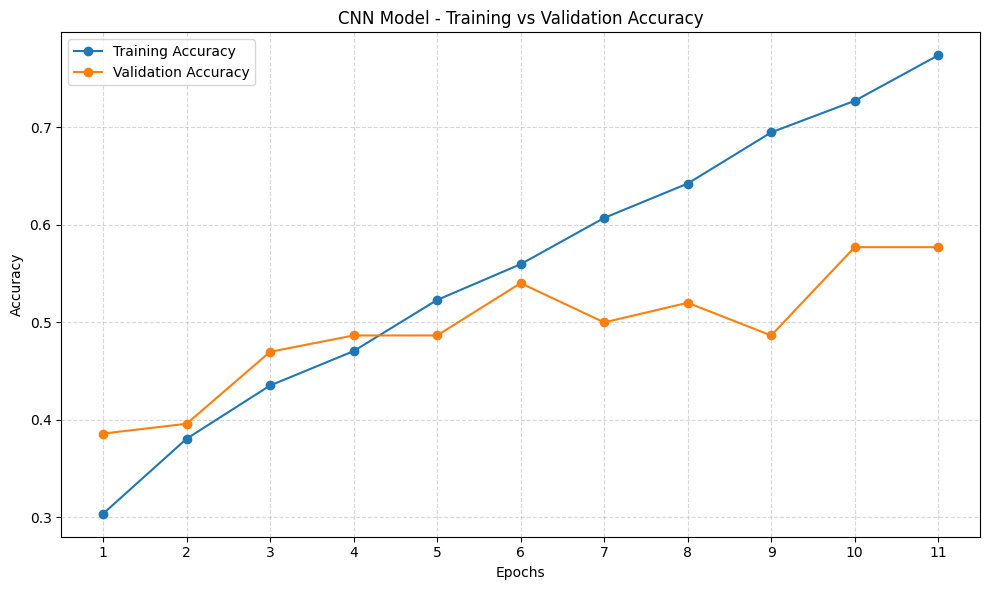

Accuracy graph saved: /content/Waste_Image_Classification/outputs/training_accuracy.png


In [54]:
# Plot training and validation accuracy

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, completed_epochs + 1),
    training_accuracy,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    range(1, completed_epochs + 1),
    validation_accuracy,
    marker="o",
    label="Validation Accuracy"
)

plt.title("CNN Model - Training vs Validation Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.xticks(range(1, completed_epochs + 1))

plt.legend()

plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

# Save accuracy graph

accuracy_graph_path = os.path.join(
    OUTPUT_DIR,
    "training_accuracy.png"
)

plt.savefig(
    accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy graph saved:", accuracy_graph_path)

**Plot training and validation loss**

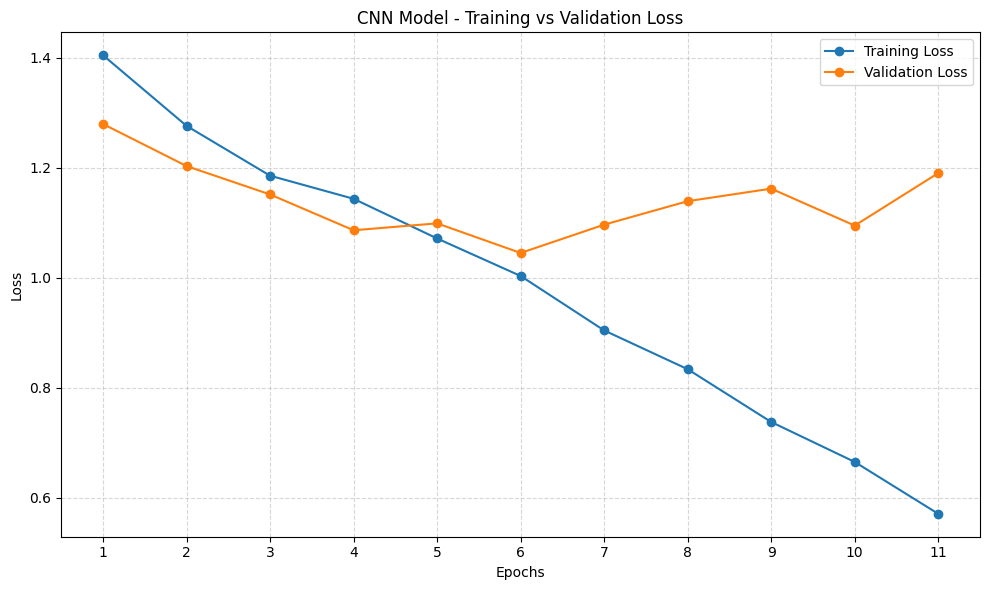

Loss graph saved: /content/Waste_Image_Classification/outputs/training_loss.png


In [55]:
# Plot training and validation loss

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, completed_epochs + 1),
    training_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, completed_epochs + 1),
    validation_loss,
    marker="o",
    label="Validation Loss"
)

plt.title("CNN Model - Training vs Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.xticks(range(1, completed_epochs + 1))

plt.legend()

plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

# Save loss graph

loss_graph_path = os.path.join(
    OUTPUT_DIR,
    "training_loss.png"
)

plt.savefig(
    loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Loss graph saved:", loss_graph_path)

**Save training history**

In [56]:
# Save training history as CSV

history_csv_path = os.path.join(
    OUTPUT_DIR,
    "training_history.csv"
)

training_results.to_csv(
    history_csv_path,
    index=False
)

print("Training history saved successfully!")

print("Location:", history_csv_path)

Training history saved successfully!
Location: /content/Waste_Image_Classification/outputs/training_history.csv


**Save the final trained model**

In [60]:
# Save final trained model

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "waste_cnn_model.keras"
)

model.save(FINAL_MODEL_PATH)

print("TRAINED CNN MODEL SAVED!")
print("=" * 45)

print("Model Location:", FINAL_MODEL_PATH)

print("Best Checkpoint:", BEST_MODEL_PATH)

TRAINED CNN MODEL SAVED!
Model Location: /content/Waste_Image_Classification/models/waste_cnn_model.keras
Best Checkpoint: /content/Waste_Image_Classification/models/best_waste_cnn_model.keras


**Load the saved model and verify it**

In [62]:
# Load the saved CNN model

loaded_model = tf.keras.models.load_model(
    FINAL_MODEL_PATH
)

print("Saved model loaded successfully!")

print("\nLoaded Model Summary:")

loaded_model.summary()

Saved model loaded successfully!

Loaded Model Summary:


Model: "Waste_Classification_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv2D_1 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling_1 (MaxPooling2D)     │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2D_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling_2 (MaxPooling2D)     │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2D_3 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling_3 (MaxPooling2D)     │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten_Layer (Flatten)         │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_Hidden (Dense)            │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_Layer (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,864,590 (49.07 MB)

 Trainable params: 4,288,196 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,576,394 (32.72 MB)

**Verify model prediction output**

In [63]:
# Verify prediction using the saved model

sample_image = X_test[:1]

sample_prediction = loaded_model.predict(
    sample_image,
    verbose=0
)

print("Prediction Output Shape:",
      sample_prediction.shape)

print("\nClass Probabilities:")

for index, probability in enumerate(sample_prediction[0]):

    print(
        f"{index_to_class[index].capitalize()}: "
        f"{probability * 100:.2f}%"
    )

print("\nProbability Sum:",
      round(np.sum(sample_prediction[0]), 4))

Prediction Output Shape: (1, 4)

Class Probabilities:
Paper: 37.47%
Plastic: 17.93%
Glass: 38.44%
Metal: 6.16%

Probability Sum: 1.0


**Generate final training summary**

In [64]:
# Final CNN training summary

print("=" * 55)
print("WASTE IMAGE CLASSIFICATION - TRAINING SUMMARY")
print("=" * 55)

print("\nMODEL INFORMATION")

print("Model Name:", model.name)
print("Total Parameters:", model.count_params())

print("\nTRAINING CONFIGURATION")

print("Optimizer: Adam")
print("Learning Rate:", LEARNING_RATE)
print("Loss Function: Sparse Categorical Crossentropy")
print("Batch Size:", BATCH_SIZE)
print("Maximum Epochs:", EPOCHS)

print("\nTRAINING RESULTS")

print("Completed Epochs:", completed_epochs)

print("Best Epoch:", best_epoch)

print("Best Validation Accuracy:",
      round(best_val_accuracy * 100, 2), "%")

print("Best Validation Loss:",
      round(best_val_loss, 4))

print("\nGENERATED FILES")

print("1. waste_cnn_model.keras")
print("2. best_waste_cnn_model.keras")
print("3. training_accuracy.png")
print("4. training_loss.png")
print("5. training_history.csv")

print("\nTRAINED MODEL LOCATION:")
print(FINAL_MODEL_PATH)

print("\nSTEP 4 COMPLETED SUCCESSFULLY!")

print("=" * 55)

WASTE IMAGE CLASSIFICATION - TRAINING SUMMARY

MODEL INFORMATION
Model Name: Waste_Classification_CNN
Total Parameters: 4288196

TRAINING CONFIGURATION
Optimizer: Adam
Learning Rate: 0.001
Loss Function: Sparse Categorical Crossentropy
Batch Size: 32
Maximum Epochs: 20

TRAINING RESULTS
Completed Epochs: 11
Best Epoch: 6
Best Validation Accuracy: 54.03 %
Best Validation Loss: 1.0451

GENERATED FILES
1. waste_cnn_model.keras
2. best_waste_cnn_model.keras
3. training_accuracy.png
4. training_loss.png
5. training_history.csv

TRAINED MODEL LOCATION:
/content/Waste_Image_Classification/models/waste_cnn_model.keras

STEP 4 COMPLETED SUCCESSFULLY!


#Stage 5 – Model Evaluation and Performance Analysis


Import evaluation libraries

In [65]:
# Import required evaluation libraries

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


**Verify testing dataset**

In [66]:
# Verify testing dataset

print("TEST DATASET VERIFICATION")
print("=" * 45)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

print("Image Dimensions:", X_test.shape[1:])
print("Number of Classes:", len(CLASS_NAMES))

print("\nAvailable Categories:")

for index, name in index_to_class.items():
    print(index, ":", name)

assert X_test.shape[1:] == (128, 128, 3)
assert len(X_test) == len(y_test)
assert len(np.unique(y_test)) == 4

print("\nTesting dataset verification successful!")

TEST DATASET VERIFICATION
Testing Images: (299, 128, 128, 3)
Testing Labels: (299,)
Image Dimensions: (128, 128, 3)
Number of Classes: 4

Available Categories:
0 : paper
1 : plastic
2 : glass
3 : metal

Testing dataset verification successful!


**Load the saved trained model**

In [67]:
# Define saved model path

PROJECT_DIR = "/content/Waste_Image_Classification"

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "outputs"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "waste_cnn_model.keras"
)

# Verify model availability

if not os.path.exists(FINAL_MODEL_PATH):

    raise FileNotFoundError(
        "Trained model not found. "
        "Restore the saved model or execute Step 4 training."
    )

# Load trained model

loaded_model = tf.keras.models.load_model(
    FINAL_MODEL_PATH
)

print("Trained CNN model loaded successfully!")

print("\nModel Architecture:")

loaded_model.summary()

Trained CNN model loaded successfully!

Model Architecture:


Model: "Waste_Classification_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv2D_1 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling_1 (MaxPooling2D)     │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2D_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling_2 (MaxPooling2D)     │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2D_3 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling_3 (MaxPooling2D)     │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten_Layer (Flatten)         │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_Hidden (Dense)            │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_Layer (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,864,590 (49.07 MB)

 Trainable params: 4,288,196 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,576,394 (32.72 MB)

**Evaluate the CNN model**

In [68]:
# Evaluate model on unseen testing data

test_loss, test_accuracy = loaded_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTEST DATASET PERFORMANCE")
print("=" * 45)

print("Test Loss:", round(float(test_loss), 4))

print(
    "Test Accuracy:",
    round(float(test_accuracy * 100), 2),
    "%"
)

10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 297ms/step - accuracy: 0.5385 - loss: 1.0410

TEST DATASET PERFORMANCE
Test Loss: 1.041
Test Accuracy: 53.85 %


**Generate predictions for all test images**

In [69]:
# Generate predictions for testing dataset

y_pred_prob = loaded_model.predict(
    X_test,
    batch_size=32,
    verbose=1
)

# Convert probabilities into predicted class indices

y_pred = np.argmax(
    y_pred_prob,
    axis=1
)

# Actual labels

y_true = y_test

print("\nPREDICTION RESULTS")
print("=" * 45)

print("Actual Labels Shape:", y_true.shape)

print("Predicted Labels Shape:", y_pred.shape)

print("Prediction Probabilities Shape:", y_pred_prob.shape)

print("\nFirst 10 Actual Labels:")
print(y_true[:10])

print("\nFirst 10 Predicted Labels:")
print(y_pred[:10])

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step

PREDICTION RESULTS
Actual Labels Shape: (299,)
Predicted Labels Shape: (299,)
Prediction Probabilities Shape: (299, 4)

First 10 Actual Labels:
[3 0 2 3 3 1 1 2 3 2]

First 10 Predicted Labels:
[2 0 2 0 3 1 1 2 3 3]


**Calculate accuracy, precision, recall and F1-score**

In [70]:
# Calculate classification metrics

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision_macro = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

# Calculate weighted metrics

precision_weighted = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print("OVERALL MODEL PERFORMANCE")
print("=" * 45)

print(f"Accuracy          : {accuracy * 100:.2f}%")
print(f"Macro Precision   : {precision_macro:.4f}")
print(f"Macro Recall      : {recall_macro:.4f}")
print(f"Macro F1-score    : {f1_macro:.4f}")

print("\nWEIGHTED METRICS")

print(f"Weighted Precision: {precision_weighted:.4f}")
print(f"Weighted Recall   : {recall_weighted:.4f}")
print(f"Weighted F1-score : {f1_weighted:.4f}")

OVERALL MODEL PERFORMANCE
Accuracy          : 53.85%
Macro Precision   : 0.5494
Macro Recall      : 0.5377
Macro F1-score    : 0.5353

WEIGHTED METRICS
Weighted Precision: 0.5586
Weighted Recall   : 0.5385
Weighted F1-score : 0.5395


**Generate the classification report**

In [71]:
# Generate classification report

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

# Convert report into DataFrame

report_df = pd.DataFrame(report).transpose()

print("CLASSIFICATION REPORT")
print("=" * 60)

display(report_df.round(4))

CLASSIFICATION REPORT


,precision,recall,f1-score,support
paper,0.6935,0.4831,0.5695,89.0000
plastic,0.4592,0.6164,0.5263,73.0000
glass,0.5357,0.5921,0.5625,76.0000
metal,0.5091,0.4590,0.4828,61.0000
accuracy,0.5385,0.5385,0.5385,0.5385
macro avg,0.5494,0.5377,0.5353,299.0000
weighted avg,0.5586,0.5385,0.5395,299.0000


**Create a performance summary table**

In [72]:
# Create performance summary

performance_summary = pd.DataFrame({

    "Metric": [
        "Test Accuracy",
        "Test Loss",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-score"
    ],

    "Obtained Value": [
        accuracy,
        test_loss,
        precision_macro,
        recall_macro,
        f1_macro,
        precision_weighted,
        recall_weighted,
        f1_weighted
    ]
})

print("FINAL PERFORMANCE SUMMARY")

display(
    performance_summary.round(4)
)

FINAL PERFORMANCE SUMMARY


,Metric,Obtained Value
0,Test Accuracy,0.5385
1,Test Loss,1.0410
2,Macro Precision,0.5494
3,Macro Recall,0.5377
4,Macro F1-score,0.5353
5,Weighted Precision,0.5586
6,Weighted Recall,0.5385
7,Weighted F1-score,0.5395


**Calculate confusion matrix**

In [73]:
# Calculate confusion matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

print("CONFUSION MATRIX")
print("=" * 40)

print(cm)

CONFUSION MATRIX
[[43 24  9 13]
 [ 5 45 19  4]
 [ 4 17 45 10]
 [10 12 11 28]]


**Plot confusion matrix heatmap**

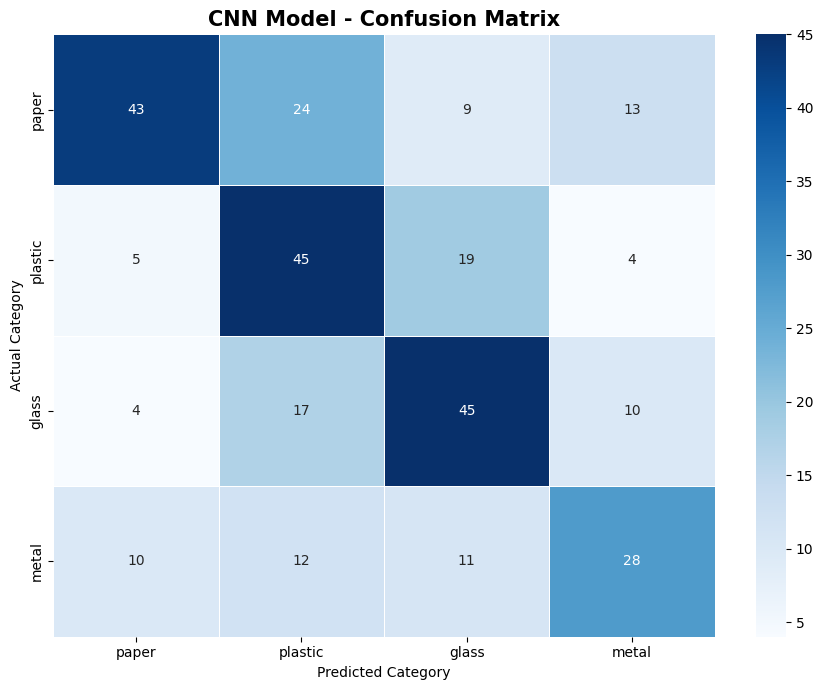

Confusion matrix saved: /content/Waste_Image_Classification/outputs/confusion_matrix.png


In [74]:
# Visualize confusion matrix

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.5
)

plt.title(
    "CNN Model - Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Category")

plt.ylabel("Actual Category")

plt.tight_layout()

# Save confusion matrix

confusion_path = os.path.join(
    OUTPUT_DIR,
    "confusion_matrix.png"
)

plt.savefig(
    confusion_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved:", confusion_path)

**Plot normalized confusion matrix**

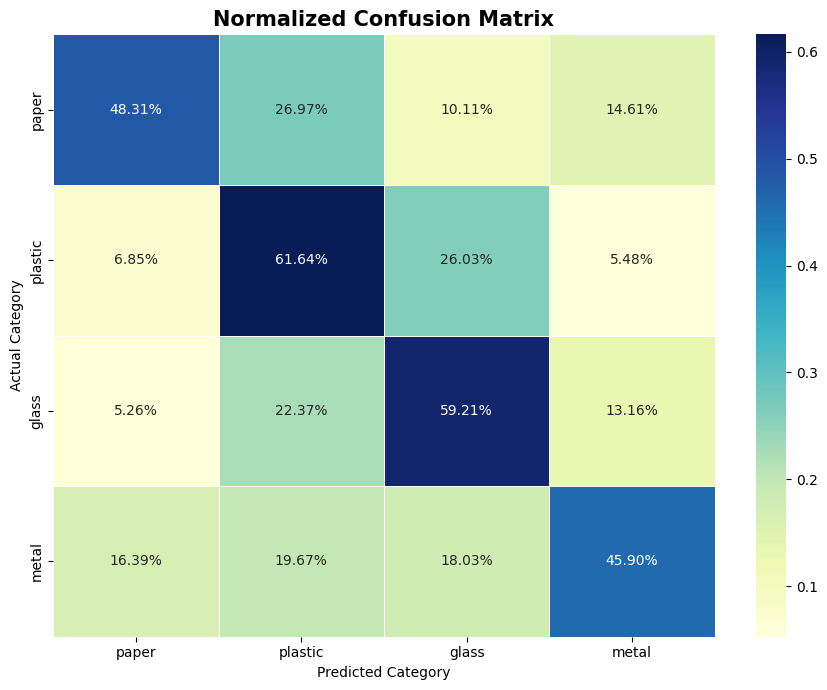

In [75]:
# Calculate normalized confusion matrix

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    normalize="true"
)

# Plot normalized matrix

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2%",
    cmap="YlGnBu",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.5
)

plt.title(
    "Normalized Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Category")

plt.ylabel("Actual Category")

plt.tight_layout()

# Save graph

normalized_cm_path = os.path.join(
    OUTPUT_DIR,
    "normalized_confusion_matrix.png"
)

plt.savefig(
    normalized_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Identify misclassified images**

In [76]:
# Identify incorrect predictions

misclassified_indices = np.where(
    y_true != y_pred
)[0]

correct_indices = np.where(
    y_true == y_pred
)[0]

print("PREDICTION ANALYSIS")
print("=" * 45)

print("Total Test Images:", len(y_true))

print("Correct Predictions:", len(correct_indices))

print("Incorrect Predictions:", len(misclassified_indices))

print(
    "Misclassification Rate:",
    round(len(misclassified_indices) / len(y_true) * 100, 2),
    "%"
)

PREDICTION ANALYSIS
Total Test Images: 299
Correct Predictions: 161
Incorrect Predictions: 138
Misclassification Rate: 46.15 %


**Display misclassified images**

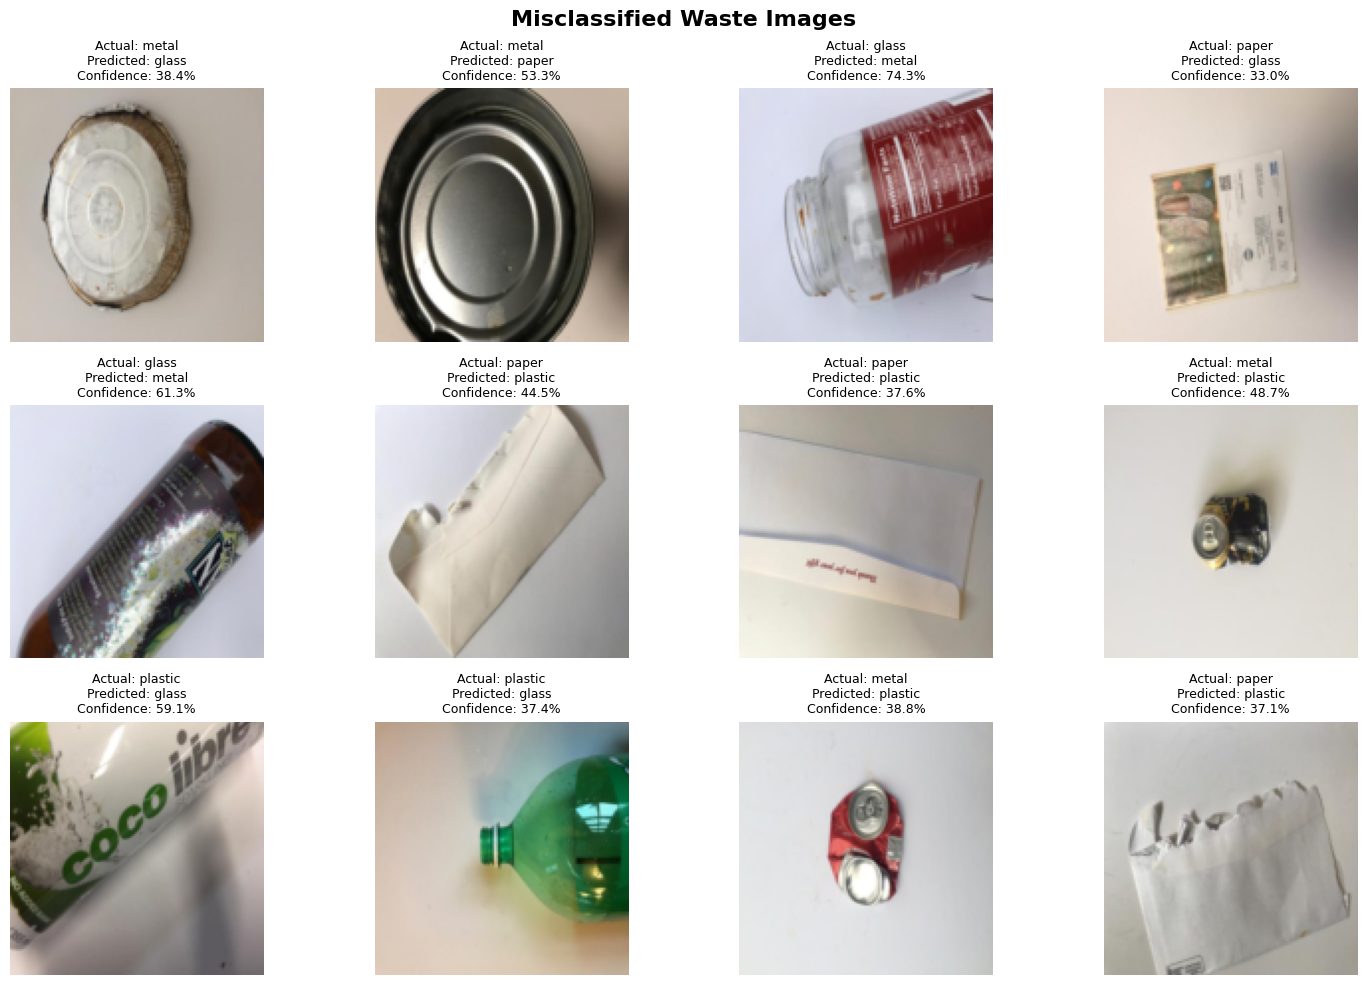

Misclassified image visualization saved!


In [77]:
# Display misclassified images

num_images = min(
    12,
    len(misclassified_indices)
)

if num_images == 0:

    print("No misclassified images found in the test dataset.")

else:

    plt.figure(figsize=(15, 10))

    for i, image_index in enumerate(
        misclassified_indices[:num_images]
    ):

        plt.subplot(3, 4, i + 1)

        # Display test image

        plt.imshow(X_test[image_index])

        # Actual category

        actual_label = index_to_class[
            int(y_true[image_index])
        ]

        # Predicted category

        predicted_label = index_to_class[
            int(y_pred[image_index])
        ]

        # Prediction confidence

        confidence = np.max(
            y_pred_prob[image_index]
        ) * 100

        plt.title(
            f"Actual: {actual_label}\n"
            f"Predicted: {predicted_label}\n"
            f"Confidence: {confidence:.1f}%",
            fontsize=9
        )

        plt.axis("off")

    plt.suptitle(
        "Misclassified Waste Images",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    # Save visualization

    misclassified_path = os.path.join(
        OUTPUT_DIR,
        "misclassified_images.png"
    )

    plt.savefig(
        misclassified_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Misclassified image visualization saved!")

**Save classification report as CSV**

In [78]:
# Save classification report

classification_csv_path = os.path.join(
    OUTPUT_DIR,
    "classification_report.csv"
)

report_df.to_csv(
    classification_csv_path
)

print("Classification report saved!")
print(classification_csv_path)

Classification report saved!
/content/Waste_Image_Classification/outputs/classification_report.csv


**Save performance metrics as CSV**

In [79]:
# Save overall performance metrics

performance_csv_path = os.path.join(
    OUTPUT_DIR,
    "performance_metrics.csv"
)

performance_summary.to_csv(
    performance_csv_path,
    index=False
)

print("Performance metrics saved!")
print(performance_csv_path)

Performance metrics saved!
/content/Waste_Image_Classification/outputs/performance_metrics.csv


**Save actual and predicted labels**

In [80]:
# Create prediction results DataFrame

prediction_results = pd.DataFrame({

    "Actual Label": [
        index_to_class[int(label)]
        for label in y_true
    ],

    "Predicted Label": [
        index_to_class[int(label)]
        for label in y_pred
    ],

    "Confidence": np.max(
        y_pred_prob,
        axis=1
    ),

    "Correct Prediction": (
        y_true == y_pred
    )
})

# Save prediction results

prediction_csv_path = os.path.join(
    OUTPUT_DIR,
    "test_predictions.csv"
)

prediction_results.to_csv(
    prediction_csv_path,
    index=False
)

print("Prediction results saved!")
print(prediction_csv_path)

display(prediction_results.head(10))

Prediction results saved!
/content/Waste_Image_Classification/outputs/test_predictions.csv


,Actual Label,Predicted Label,Confidence,Correct Prediction
0,metal,glass,0.384402,False
1,paper,paper,0.953043,True
2,glass,glass,0.387505,True
3,metal,paper,0.532945,False
4,metal,metal,0.859115,True
5,plastic,plastic,0.404474,True
6,plastic,plastic,0.814931,True
7,glass,glass,0.473031,True
8,metal,metal,0.714093,True
9,glass,metal,0.743289,False


**Save evaluation results as JSON**

In [81]:
# Prepare evaluation results

evaluation_results = {

    "model": "Waste Classification CNN",

    "dataset": "TrashNet",

    "classes": CLASS_NAMES,

    "test_images": int(len(y_true)),

    "test_loss": float(test_loss),

    "test_accuracy": float(accuracy),

    "macro_precision": float(precision_macro),

    "macro_recall": float(recall_macro),

    "macro_f1_score": float(f1_macro),

    "weighted_precision": float(precision_weighted),

    "weighted_recall": float(recall_weighted),

    "weighted_f1_score": float(f1_weighted),

    "correct_predictions": int(len(correct_indices)),

    "incorrect_predictions": int(len(misclassified_indices)),

    "confusion_matrix": cm.tolist()
}

# Save JSON file

evaluation_json_path = os.path.join(
    OUTPUT_DIR,
    "evaluation_results.json"
)

with open(evaluation_json_path, "w") as file:

    json.dump(
        evaluation_results,
        file,
        indent=4
    )

print("Evaluation results saved as JSON!")
print(evaluation_json_path)

Evaluation results saved as JSON!
/content/Waste_Image_Classification/outputs/evaluation_results.json


**Final evaluation summary**

In [82]:
# Final model evaluation summary

print("=" * 60)

print("WASTE IMAGE CLASSIFICATION - FINAL EVALUATION")

print("=" * 60)

print("\nTEST PERFORMANCE")

print(f"Test Accuracy     : {accuracy * 100:.2f}%")

print(f"Test Loss         : {test_loss:.4f}")

print(f"Macro Precision   : {precision_macro:.4f}")

print(f"Macro Recall      : {recall_macro:.4f}")

print(f"Macro F1-score    : {f1_macro:.4f}")

print("\nPREDICTION SUMMARY")

print("Total Images       :", len(y_true))

print("Correct Predictions:", len(correct_indices))

print("Incorrect Predictions:", len(misclassified_indices))

print("\nSAVED OUTPUT FILES")

for filename in sorted(os.listdir(OUTPUT_DIR)):

    print("✔", filename)

print("\nSTEP 5 COMPLETED SUCCESSFULLY!")

print("=" * 60)

WASTE IMAGE CLASSIFICATION - FINAL EVALUATION

TEST PERFORMANCE
Test Accuracy     : 53.85%
Test Loss         : 1.0410
Macro Precision   : 0.5494
Macro Recall      : 0.5377
Macro F1-score    : 0.5353

PREDICTION SUMMARY
Total Images       : 299
Correct Predictions: 161
Incorrect Predictions: 138

SAVED OUTPUT FILES
✔ class_distribution.png
✔ classification_report.csv
✔ cnn_architecture.json
✔ confusion_matrix.png
✔ dataset_split.png
✔ evaluation_results.json
✔ misclassified_images.png
✔ normalized_confusion_matrix.png
✔ performance_metrics.csv
✔ preprocessed_images.png
✔ sample_images.png
✔ test_predictions.csv
✔ training_accuracy.png
✔ training_history.csv
✔ training_loss.png

STEP 5 COMPLETED SUCCESSFULLY!
